<a href="https://colab.research.google.com/github/LucaWata/Calculo_Numerico/blob/main/tarefa_interpolacao_erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**

### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

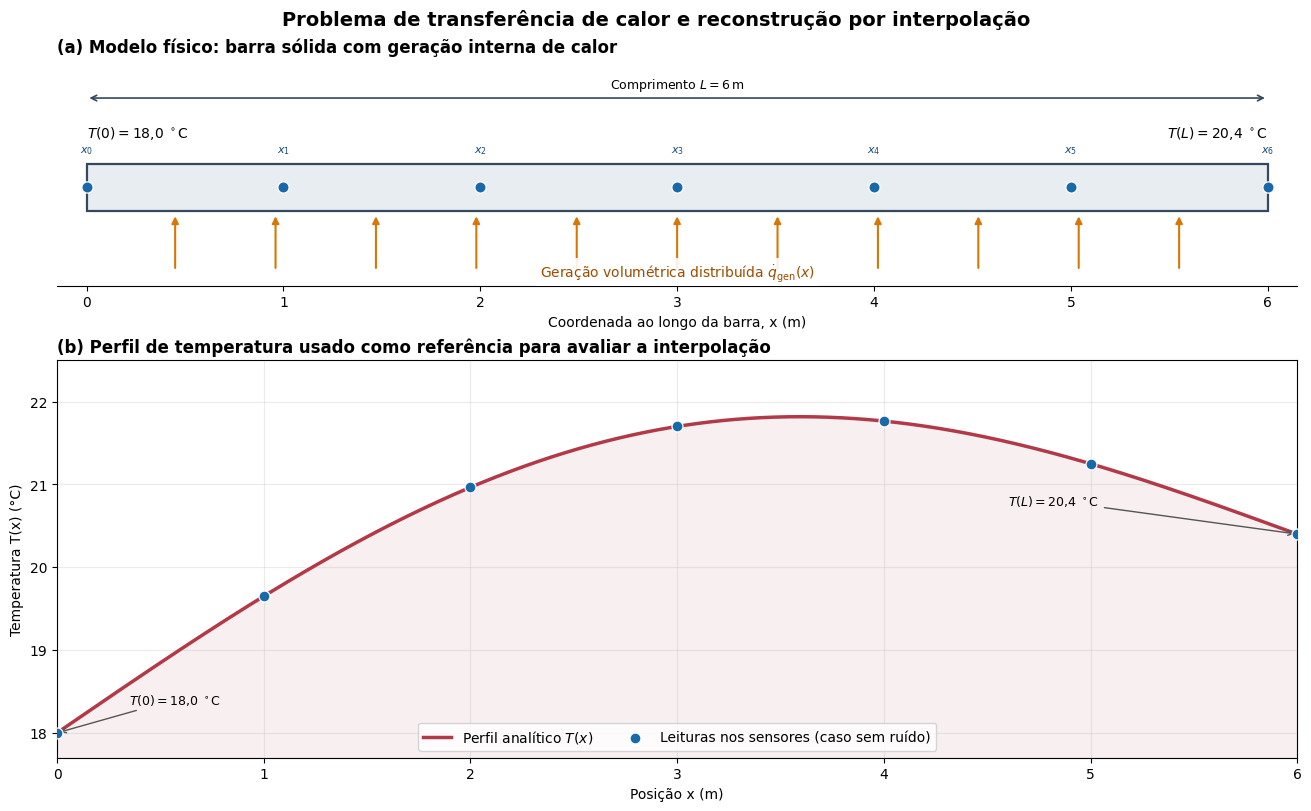

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [ ]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


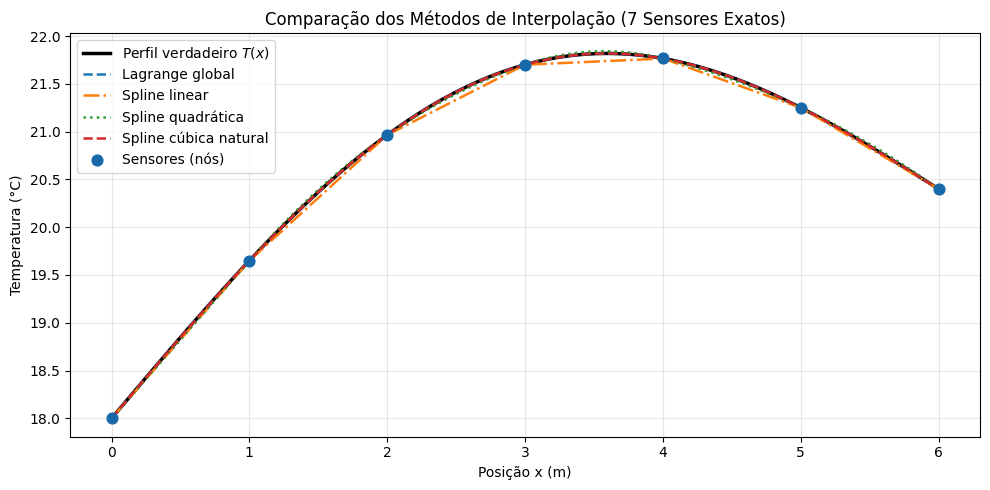

In [ ]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# 1. Calcular e exibir a tabela de métricas na malha fina
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

# 2. Gráfico sobrepondo os quatro métodos à função verdadeira
plt.figure(figsize=(10, 5))
plt.plot(x_fino, T_fino, 'k-', linewidth=2.5, label='Perfil verdadeiro $T(x)$', zorder=2)

estilos = ['--', '-.', ':', '--']
for (nome, metodo), estilo in zip(metodos_7.items(), estilos):
    plt.plot(x_fino, metodo(x_fino), linestyle=estilo, linewidth=1.8, label=nome)

plt.scatter(x_nos_7, y_nos_7, color='#1769aa', s=60, zorder=5, label='Sensores (nós)')

plt.title('Comparação dos Métodos de Interpolação (7 Sensores Exatos)')
plt.xlabel('Posição x (m)')
plt.ylabel('Temperatura (°C)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

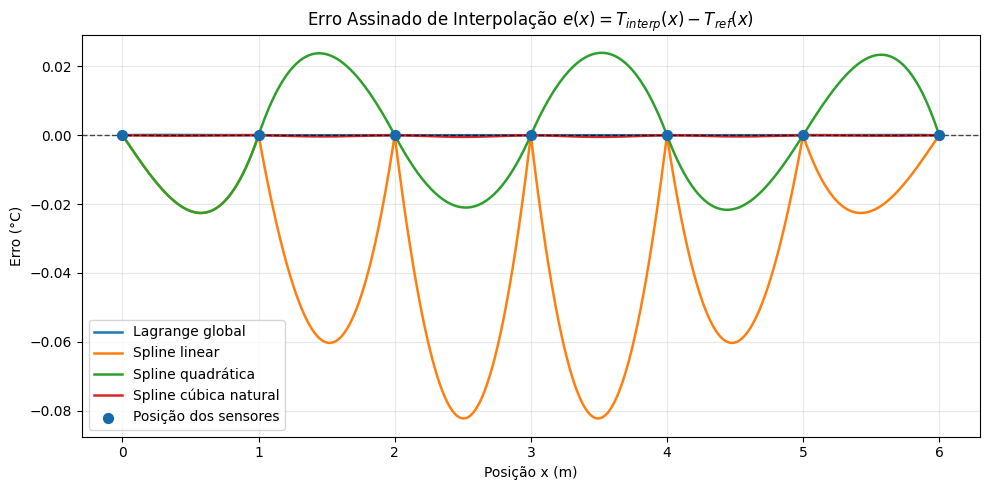

In [ ]:
# Gráfico dos erros assinados método a método
plt.figure(figsize=(10, 5))

for nome, metodo in metodos_7.items():
    erro = metodo(x_fino) - T_fino
    plt.plot(x_fino, erro, linewidth=1.8, label=nome)

# Linha de referência de erro zero e marcação das posições dos sensores
plt.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
plt.scatter(x_nos_7, np.zeros_like(x_nos_7), color='#1769aa', s=50, zorder=5, label='Posição dos sensores')

plt.title('Erro Assinado de Interpolação $e(x) = T_{interp}(x) - T_{ref}(x)$')
plt.xlabel('Posição x (m)')
plt.ylabel('Erro (°C)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

,N,Distribuição,Erro máximo (°C),RMSE (°C)
0,5,Equiespaçados,4.530257e-03,2.159567e-03
1,5,Chebyshev-Lobatto,2.326599e-03,1.532697e-03
2,9,Equiespaçados,1.043537e-06,3.438146e-07
3,9,Chebyshev-Lobatto,2.167582e-07,1.202332e-07
4,13,Equiespaçados,5.919887e-11,1.545512e-11
5,13,Chebyshev-Lobatto,3.627321e-12,1.932105e-12
6,17,Equiespaçados,1.989520e-12,2.445428e-13
7,17,Chebyshev-Lobatto,1.421085e-14,3.884340e-15


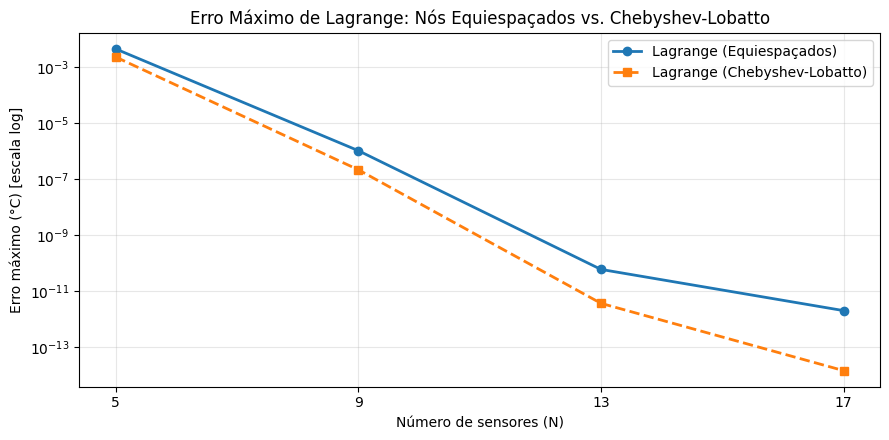

In [ ]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k * np.pi / (N - 1))
    return np.sort((a + b) / 2 + (b - a) * z / 2)

valores_N = [5, 9, 13, 17]
resultados_etapa2 = []

for N in valores_N:
    # 1. Nós equiespaçados
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)
    interp_eq = BarycentricInterpolator(x_eq, y_eq)
    erro_eq = interp_eq(x_fino) - T_fino

    resultados_etapa2.append({
        "N": N,
        "Distribuição": "Equiespaçados",
        "Erro máximo (°C)": np.max(np.abs(erro_eq)),
        "RMSE (°C)": np.sqrt(np.mean(erro_eq**2))
    })

    # 2. Nós de Chebyshev-Lobatto
    x_cheb = nos_chebyshev_lobatto(x_min, x_max, N)
    y_cheb = temperatura_real(x_cheb)
    interp_cheb = BarycentricInterpolator(x_cheb, y_cheb)
    erro_cheb = interp_cheb(x_fino) - T_fino

    resultados_etapa2.append({
        "N": N,
        "Distribuição": "Chebyshev-Lobatto",
        "Erro máximo (°C)": np.max(np.abs(erro_cheb)),
        "RMSE (°C)": np.sqrt(np.mean(erro_cheb**2))
    })

tabela_nos = pd.DataFrame(resultados_etapa2)
display(tabela_nos)

# Gráfico comparativo do Erro Máximo em escala logarítmica
plt.figure(figsize=(9, 4.5))
for dist, marcador in [("Equiespaçados", "o-"), ("Chebyshev-Lobatto", "s--")]:
    sub = tabela_nos[tabela_nos["Distribuição"] == dist]
    plt.semilogy(sub["N"], sub["Erro máximo (°C)"], marcador, linewidth=2, label=f"Lagrange ({dist})")

plt.title("Erro Máximo de Lagrange: Nós Equiespaçados vs. Chebyshev-Lobatto")
plt.xlabel("Número de sensores (N)")
plt.ylabel("Erro máximo (°C) [escala log]")
plt.xticks(valores_N)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

Não, para $N$ pequeno a moderado $(N \le 15)$, o Lagrange com Chebyshev (e até o equiespaçado) entrega precisão máxima com custo baixo. Para $N$ grande $(N > 20)$, o Lagrange equiespaçado degrada numericamente, e a Spline cúbica natural torna-se superior em velocidade de avaliação (e muito mais robusta caso surja qualquer ruído nos sensores)

,N,Método,Erro máximo (°C),RMSE (°C),Tempo construção (µs),Tempo avaliação (µs)
0,4,Lagrange equiespaçado,1.090393e-01,6.829596e-02,73.422020,180.202110
1,4,Lagrange Chebyshev,1.429774e-01,8.094463e-02,71.769945,179.351585
2,4,Spline cúbica natural,1.017696e-02,4.786615e-03,268.586210,43.486885
3,10,Lagrange equiespaçado,7.516743e-07,2.375289e-07,115.702795,279.515545
4,10,Lagrange Chebyshev,2.337620e-07,1.344155e-07,126.369965,341.895670
5,10,Spline cúbica natural,9.963236e-05,4.517820e-05,181.251775,42.997240
6,20,Lagrange equiespaçado,1.650591e-11,1.175682e-12,338.679770,638.056945
7,20,Lagrange Chebyshev,1.421085e-14,4.123791e-15,320.851415,614.507335
8,20,Spline cúbica natural,4.899580e-06,2.211105e-06,293.974810,80.176900
9,30,Lagrange equiespaçado,1.424163e-08,9.096330e-10,259.480460,622.140950


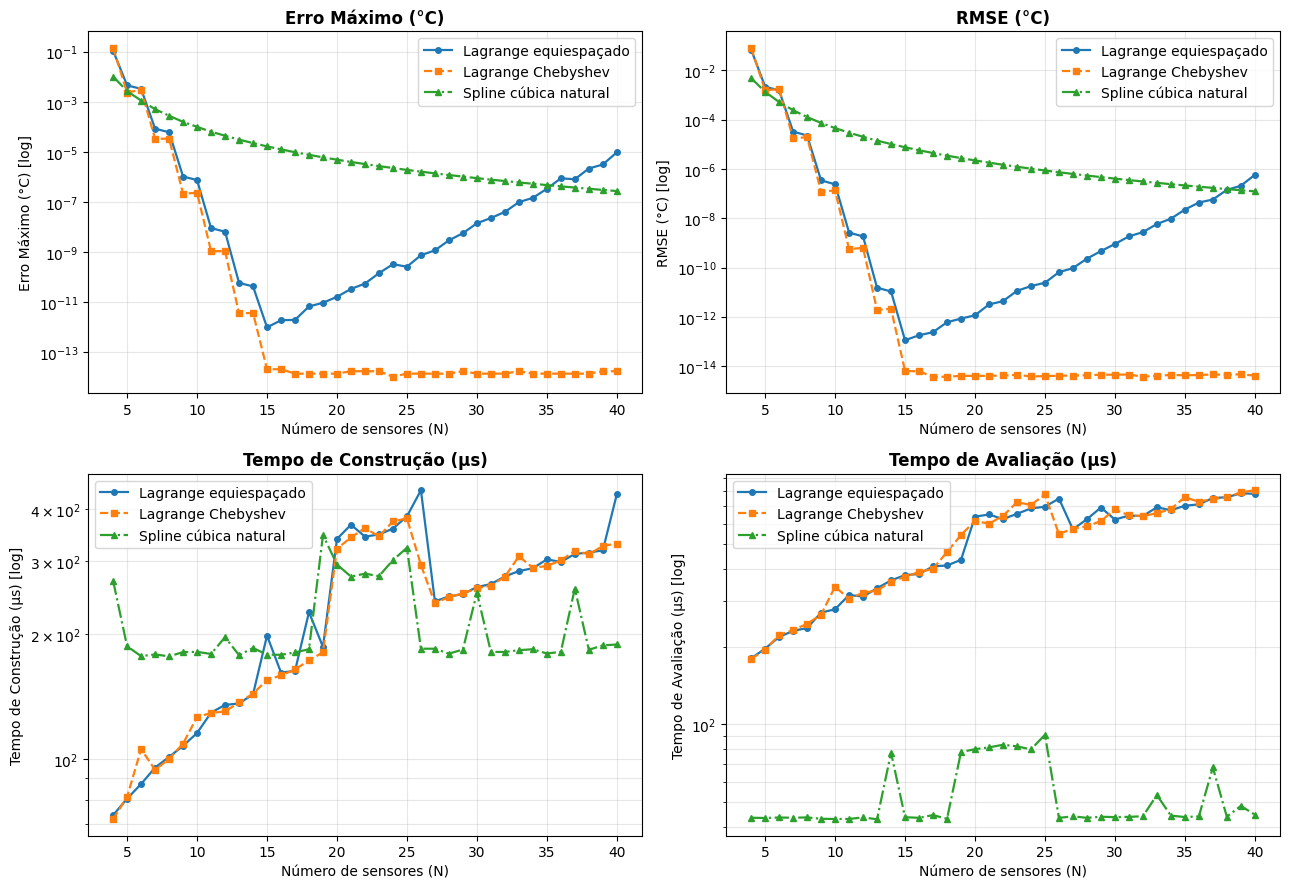

In [ ]:
import time

valores_N_etapa3 = np.arange(4, 41)
resultados_etapa3 = []

# Número de repetições para estabilizar a medição de tempos muito curtos
n_rep_build = 200
n_rep_eval = 200

for N in valores_N_etapa3:
    x_eq = np.linspace(x_min, x_max, N)
    y_eq = temperatura_real(x_eq)

    x_cheb = nos_chebyshev_lobatto(x_min, x_max, N)
    y_cheb = temperatura_real(x_cheb)

    configuracoes = [
        ("Lagrange equiespaçado", lambda: BarycentricInterpolator(x_eq, y_eq)),
        ("Lagrange Chebyshev", lambda: BarycentricInterpolator(x_cheb, y_cheb)),
        ("Spline cúbica natural", lambda: CubicSpline(x_eq, y_eq, bc_type="natural"))
    ]

    for nome, construtor in configuracoes:
        # 1. Tempo médio de construção (em microssegundos)
        t0 = time.perf_counter()
        for _ in range(n_rep_build):
            interp = construtor()
        t_build = (time.perf_counter() - t0) / n_rep_build * 1e6

        # 2. Tempo médio de avaliação em x_fino (em microssegundos)
        t0 = time.perf_counter()
        for _ in range(n_rep_eval):
            y_pred = interp(x_fino)
        t_eval = (time.perf_counter() - t0) / n_rep_eval * 1e6

        # 3. Métricas de erro na malha fina
        erro = y_pred - T_fino
        resultados_etapa3.append({
            "N": N,
            "Método": nome,
            "Erro máximo (°C)": np.max(np.abs(erro)),
            "RMSE (°C)": np.sqrt(np.mean(erro**2)),
            "Tempo construção (µs)": t_build,
            "Tempo avaliação (µs)": t_eval
        })

df_etapa3 = pd.DataFrame(resultados_etapa3)

# Exibir resumo para alguns valores representativos de N
display(df_etapa3[df_etapa3["N"].isin([4, 10, 20, 30, 40])].reset_index(drop=True))

# Painel gráfico (2x2): Erros e Tempos em escala logarítmica
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
estilos = {
    "Lagrange equiespaçado": ("o-", "#1f77b4"),
    "Lagrange Chebyshev": ("s--", "#ff7f0e"),
    "Spline cúbica natural": ("^-.", "#2ca02c")
}

metricas_plot = [
    ("Erro máximo (°C)", "Erro Máximo (°C)", axes[0, 0]),
    ("RMSE (°C)", "RMSE (°C)", axes[0, 1]),
    ("Tempo construção (µs)", "Tempo de Construção (µs)", axes[1, 0]),
    ("Tempo avaliação (µs)", "Tempo de Avaliação (µs)", axes[1, 1])
]

for col, titulo, ax in metricas_plot:
    for nome, (fmt, cor) in estilos.items():
        sub = df_etapa3[df_etapa3["Método"] == nome]
        ax.semilogy(sub["N"], sub[col], fmt, color=cor, markersize=4, linewidth=1.6, label=nome)
    ax.set_title(titulo, weight="bold")
    ax.set_xlabel("Número de sensores (N)")
    ax.set_ylabel(f"{titulo} [log]")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

### Recomendação Técnica — Reconstrução do Perfil Térmico da Barra

Com base nos experimentos numéricos realizados nas etapas anteriores, pode-se fazer a recomendação técnica para a instrumentação e reconstrução do campo de temperaturas $T(x)$ ao longo da barra ($L = 6\text{ m}$):

#### 1. Escolha do método com poucos sensores exatos
Para um número reduzido de sensores livres de ruído ($N \approx 7$ a $10$), recomenda-se o **polinômio global de Lagrange** (preferencialmente com nós de **Chebyshev-Lobatto** ou, caso a instalação física exija espaçamento uniforme, nós equiespaçados).
* Pois como o perfil térmico em regime estacionário com geração distribuída suave é infinitamente diferenciável, um polinômio global de grau baixo/moderado captura a curvatura senoidal com precisão superior às splines. Na Etapa 1 ($N = 7$ equiespaçados), o método de Lagrange atingiu $E_{\max} = 8,5 \times 10^{-5}\text{ °C}$ e $\text{RMSE} = 3,3 \times 10^{-5}\text{ °C}$, superando a **Spline cúbica natural** ($E_{\max} = 5,1 \times 10^{-4}\text{ °C}$ e $\text{RMSE} = 2,4 \times 10^{-4}\text{ °C}$) e superando por ordens de grandeza a spline linear ($E_{\max} = 0,082\text{ °C}$).

#### 2. Mudança de estratégia ao aumentar o número de sensores
À medida que se aumenta a quantidade de sensores ($N > 15\text{--}20$), a recomendação muda: deve-se **abandonar o polinômio global de Lagrange em nós equiespaçados** e adotar a **Spline cúbica natural** (ou manter Lagrange *apenas* se os sensores puderem ser posicionados exatamente nos nós de Chebyshev-Lobatto).
* Na Etapa 3, observou-se que o Lagrange equiespaçado atinge um mínimo de erro em torno de $N \approx 15\text{--}17$ ($\text{RMSE} \approx 2,4 \times 10^{-13}\text{ °C}$), mas volta a degradar rapidamente para $N$ maior — subindo para $E_{\max} = 1,42 \times 10^{-8}\text{ °C}$ em $N = 30$ e $E_{\max} = 9,59 \times 10^{-6}\text{ °C}$ em $N = 40$ devido ao mau condicionamento dos pesos baricêntricos na aritmética de ponto flutuante. Além disso, o custo de avaliação do polinômio global cresce linearmente com $N$ ($O(M \cdot N)$, chegando a $\sim 780\text{ }\mu\text{s}$ em $N=40$), enquanto a **Spline cúbica natural** mantém o tempo de avaliação praticamente constante ($\sim 44\text{ }\mu\text{s}$) e garante convergência monotônica e estável ($E_{\max} = 2,75 \times 10^{-7}\text{ °C}$ e $\text{RMSE} = 1,24 \times 10^{-7}\text{ °C}$ em $N=40$).

#### 3. Procedimento quando os sensores apresentam ruído
Em condições reais de campo, onde as medições contêm ruído experimental, **não se deve utilizar interpolação exata de grau elevado** (especialmente Lagrange global), pois a obrigação de passar exatamente por todos os pontos ruidosos provoca oscilações espúrias severas (*overfitting* numérico) entre os sensores, amplificando o erro nas derivadas e nos valores intermediários.
* Uma solução recomendada seria substituir a interpolação exata por **aproximação / suavização**, como **splines de suavização (*smoothing splines*)**, regressão por mínimos quadrados com polinômios de baixo grau ou filtros físicos baseados na equação de condução de calor (ajustando os parâmetros da fonte térmica e das condições de contorno aos dados ruidosos).

#### 4. Cuidados próximos às extremidades da barra
As regiões próximas a $x = 0$ e $x = L$ são as mais críticas tanto do ponto de vista físico quanto numérico:
* **Posicionamento e instrumentação:** Deve-se sempre instalar sensores diretamente nas extremidades ($x_0 = 0$ e $x_{N-1} = L$) ou o mais próximo possível delas, além de concentrar maior densidade de sensores junto às bordas (inspirado na distribuição de Chebyshev-Lobatto) para suprimir oscilações de borda.
* **Condições de contorno das splines:** Na **Spline cúbica natural**, impõe-se $T''(0) = T''(L) = 0$. Embora essa condição tenha coincidido com o perfil idealizado deste estudo ($\sin(0) = \sin(\pi) = 0$), em campo uma fonte térmica não nula nas bordas ou perdas convectivas podem gerar $T'' \neq 0$ nas extremidades, introduzindo viés local. Se o fluxo de calor (gradiente $T'$) nas extremidades for conhecido, deve-se utilizar uma **spline cúbica *clamped* (fixada)** em vez da natural.
* **Interpolação vs. Extrapolação:** Toda estimativa deve restringir-se estritamente ao domínio delimitado pelos sensores das extremidades $[x_{\min}, x_{\max}]$ (**interpolação**). Estender a curva para fora do intervalo medido (**extrapolação**) faz com que os erros de truncamento e o ruído cresçam de forma descontrolada — especialmente em polinômios de alto grau, que divergem rapidamente além dos nós extremos.

#### 5. Limitações quando a temperatura verdadeira é desconhecida
Em operação real, sem a curva analítica de referência $T_{\text{ref}}(x)$, não é possível calcular diretamente o erro verdadeiro ($E_{\max}$ ou $\text{RMSE}$ em relação à realidade física), permanecendo as seguintes limitações:
* **Invisibilidade de variações sub-malha:** Fenômenos térmicos localizados (como pontos quentes ou falhas de isolamento entre dois sensores consecutivos) não são detectados pela interpolação, gerando erros estruturais não mensuráveis apenas pelos resíduos nos nós.
* **Incerteza não quantificada automaticamente:** A interpolação determinística fornece apenas uma curva pontual, sem intervalos de confiança associados à incerteza de calibração dos termopares/sensores.
* **Necessidade de validação indireta:** Para mitigar a ausência de referência, a equipe deve recorrer à **validação cruzada (*leave-one-out*)** — omitindo um sensor por vez e medindo o $\text{RMSE}$ de previsão nele — e à verificação de consistência física (balanço global de energia e coerência do sinal de $-k\,d^2T/dx^2$ com a geração térmica esperada).